### Data pre-processing notebook for regression data.

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np

In [2]:
# load the original dataset via seaborn (your data
# is probably a csv-file instead)
df = sns.load_dataset("diamonds")

In [3]:
df.describe()

,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


<Axes: >

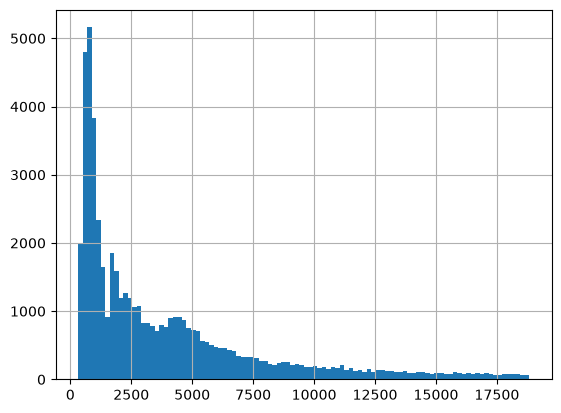

In [4]:
df['price'].hist(bins=100)

### In this dataset, the following code cell is the bare minimum

**= converting all variables into numeric format correctly (ordinal categories in this case)**

In [5]:
# convert the ordinal categories to numbers
cut_mapping = {"Fair": 1, "Good": 2, "Very Good": 3, "Premium": 4, "Ideal": 5}
df['cut'] = df['cut'].map(cut_mapping)

# convert the ordinal categories to numbers
color_mapping = {"J": 1, "I": 2, "H": 3, "G": 4, "F": 5, "E": 6, "D": 7}
df['color'] = df['color'].map(color_mapping)

# convert the ordinal categories to numbers
clarity_mapping = {"I1": 1, "SI2": 2, "SI1": 3, "VS2": 4, "VS1": 5, "VVS2": 6, "VVS1": 7, "IF": 8}
df['clarity'] = df['clarity'].map(clarity_mapping)

In [6]:
# all good here! everything's numeric
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,5,6,2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,4,6,3,59.8,61.0,326,3.89,3.84,2.31
2,0.23,2,6,5,56.9,65.0,327,4.05,4.07,2.31
3,0.29,4,2,4,62.4,58.0,334,4.20,4.23,2.63
4,0.31,2,1,2,63.3,58.0,335,4.34,4.35,2.75


<Axes: >

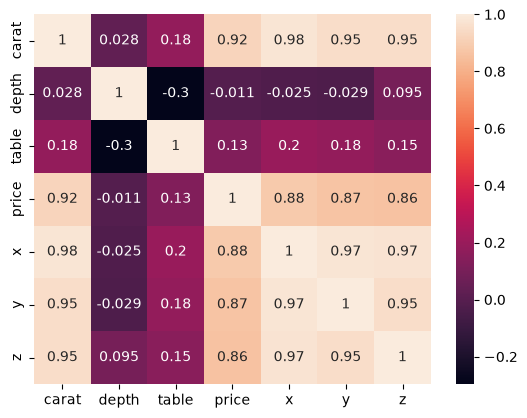

In [7]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

In [8]:
# depth seems like redundant here, the same aspects
# are already included in table and z -variables
df = df.drop("depth", axis=1)

### From this point onward, these are optional dataset optimization steps

### Optimization 1: RANSAC for undersampling / noise / outlier removal

In [9]:
from sklearn.linear_model import RANSACRegressor

# since RANSAC is a regression algorithm, X/y -split
X = df.drop("price", axis=1)
y = df['price']

# initalize RANSAC regressor and fit our data
# RANSAC needs a threshold in order to process data
# since our data is heavily skewed, we're gonna use this trick
ransac = RANSACRegressor(residual_threshold=np.std(y) * 1.5)
ransac.fit(X, y)

# now we have split the result into 
# inliers and outliers
# inliers => good data, follows the distribution nicely
# outliers => are far away from the main distribution
# the ~-sign (tilde) in pandas DataFrames means "the opposite of"
# so in this case => get everything from DataFrame EXCEPT the inliers
inlier_mask = ransac.inlier_mask_
outliers = df[~inlier_mask]
inliers = df[inlier_mask]

print(f"Inliers: {len(inliers)}")
print(f"Outliers: {len(outliers)}")

# we want to keep only the inliers (non-noisy data)
# replace the current DataFrame with the inliers
df = inliers

Inliers: 52918
Outliers: 1022


### Optimization 2: MAD for further noise removal

In [10]:
variable = "price"

# Calculate the median
median = df[variable].median()

# Calculate MAD
mad = np.median(np.abs(df[variable] - median))

# Define a threshold for noise detection
# adjust the numeric modifier for aggressiveness 
# e.g. try 2.5 or 4.5 etc.
# if the value is too high, you will find no noise (decrease in that case)
threshold = 3.0 * mad

# Detect noise
noise = df[np.abs(df[variable] - median) > threshold]

inliers = df.drop(noise.index)

print(f"Detected noise using MAD: {len(noise)} rows")

# we want to keep only the inliers (non-noisy data)
# replace the current DataFrame with the inliers
df = inliers

Detected noise using MAD: 8058 rows


### Optimization 3: Isolation Forest for outlier removal

In [11]:
# can process the whole dataset 
# and compares variables to each other instead
# of focusing on outliers on a single variable
from sklearn.ensemble import IsolationForest
import pandas as pd

# adjust the contamination rate as you see fit
# for example, if you expect 5% of the data to be outliers
# you can use 0.05 etc. 

# basically, this is how aggressive Isolation Forest will be
# increase if you think you need to detect more outliers
# decrease if you need less outliers
iso = IsolationForest(contamination=0.07) 

# REMEMBER! Isolation Forest is a machine learning algorithm
# => ALL VARIABLES HAVE TO BE NUMERIC AT THIS POINT

# fit isolation forest
y_pred = iso.fit_predict(df)

# separate outliers and inliers into separate DataFrames
outliers = df[y_pred != 1]
inliers = df[y_pred == 1]

print(f"Inliers: {len(inliers)}")
print(f"Outliers: {len(outliers)}")

# we want to keep only the inliers (non-noisy data)
# replace the current DataFrame with the inliers
df = inliers

Inliers: 41719
Outliers: 3141


<Axes: >

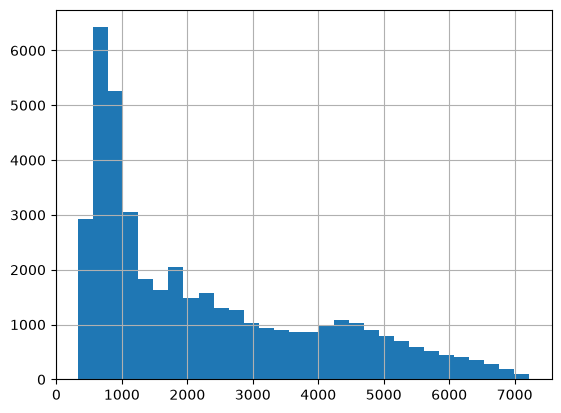

In [12]:
# it's a fairly basic beta-distribution at this point
df['price'].hist(bins=30)

In [13]:
# save this cleaned version to a csv-file
df.to_csv("processed_regression_diamonds.csv", index=None)